# 07 · Gradients, edges, and Hough lines

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–06; grayscale images, blur, and binary masks.

## What you will build and learn

- Distinguish gradients from binary edges.
- Tune Canny using visible evidence.
- Detect and filter line segments with the Hough transform.
- Build a simple document-border inspector.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Construct a scene with known boundaries
An edge is a rapid change of intensity; it is not automatically an object boundary. We will generate a clean scene, add repeatable Gaussian noise, and inspect both. Predict which image will produce more false edges before you run the next cells.


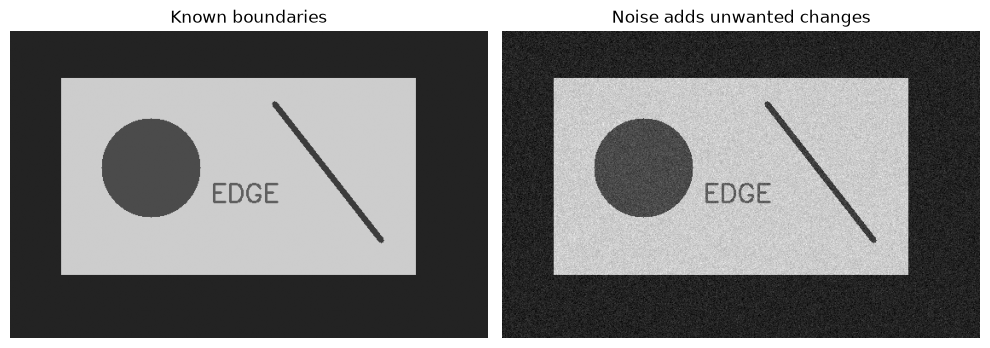

In [2]:
clean = np.full((360, 560), 35, np.uint8)
cv2.rectangle(clean, (60, 55), (475, 285), 205, -1)
cv2.circle(clean, (165, 160), 58, 75, -1)
cv2.line(clean, (310, 85), (435, 245), 60, 6)
cv2.putText(clean, 'EDGE', (235, 200), cv2.FONT_HERSHEY_SIMPLEX, 1, 95, 2)
noise = rng.normal(0, 12, clean.shape)
noisy = np.clip(clean.astype(np.float32) + noise, 0, 255).astype(np.uint8)
show_images([clean, noisy], ['Known boundaries', 'Noise adds unwanted changes'], cols=2)


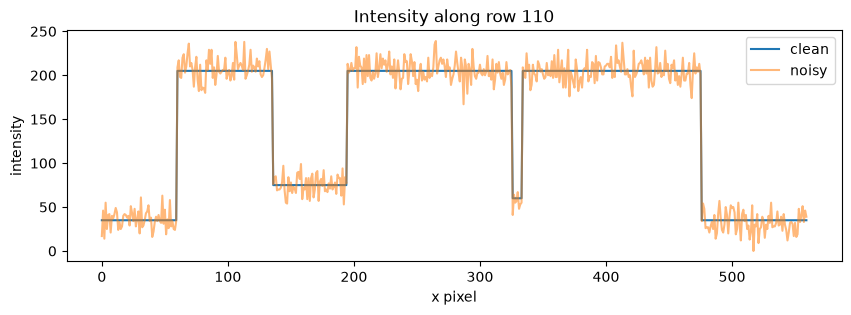

In [3]:
profile_y = 110
plt.figure(figsize=(10, 3))
plt.plot(clean[profile_y], label='clean')
plt.plot(noisy[profile_y], alpha=.55, label='noisy')
plt.title(f'Intensity along row {profile_y}')
plt.xlabel('x pixel'); plt.ylabel('intensity'); plt.legend(); plt.show()


## Step 2 — Measure signed gradients
`Sobel(image, CV_32F, dx, dy, ksize=3)` differentiates along x or y. A negative derivative is useful information: an unsigned 8-bit output would clip it. Compute in floating point; use absolute values only for display. `ksize` must be an appropriate odd kernel size.


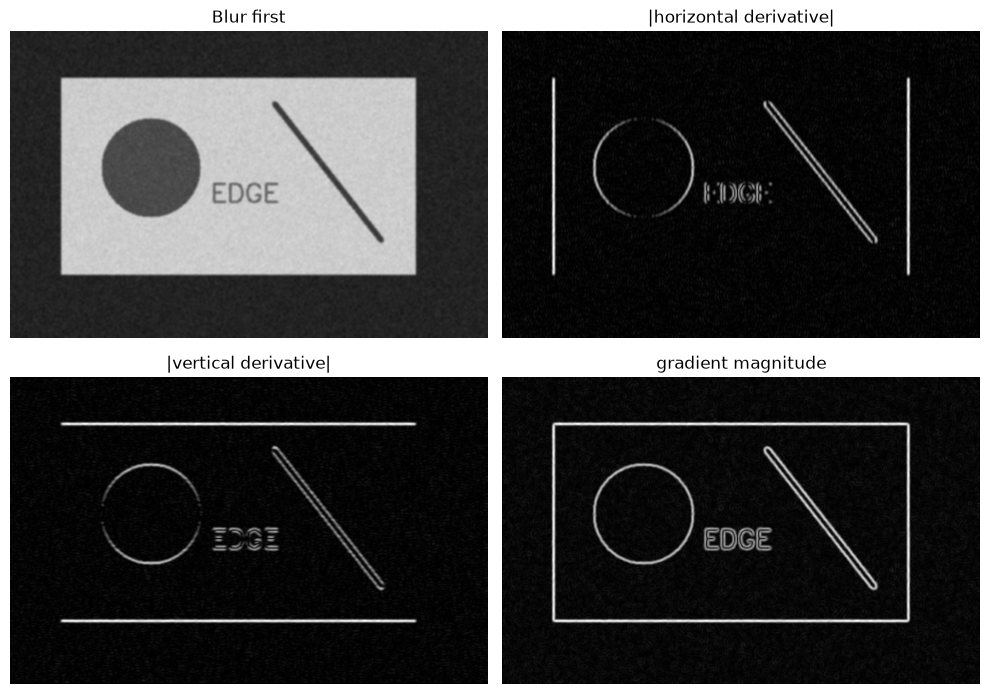

Signed x-gradient range: -434.0 429.0


In [4]:
blurred = cv2.GaussianBlur(noisy, (5, 5), 1.2)
gx = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
magnitude = cv2.magnitude(gx, gy)
show_images([blurred, np.abs(gx), np.abs(gy), magnitude],
            ['Blur first', '|horizontal derivative|', '|vertical derivative|', 'gradient magnitude'], cols=2)
print('Signed x-gradient range:', float(gx.min()), float(gx.max()))
assert gx.min() < 0 < gx.max(), 'This scene contains rising and falling edges.'


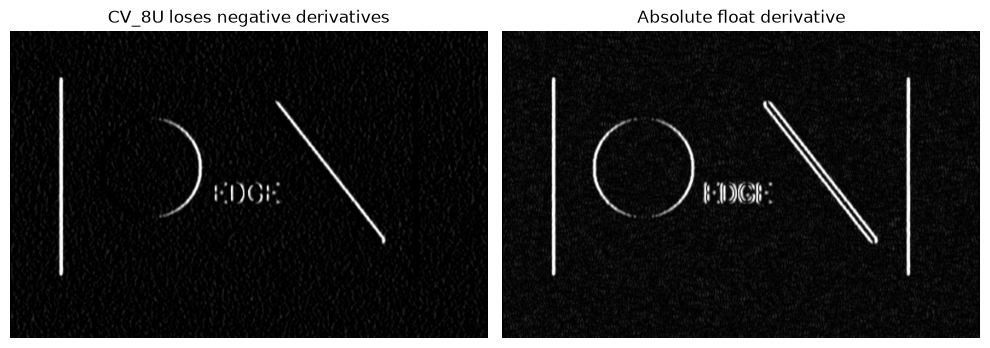

Negative gradient pixels: 97149


In [5]:
bad_unsigned = cv2.Sobel(blurred, cv2.CV_8U, 1, 0, ksize=3)
good_display = cv2.convertScaleAbs(gx)
show_images([bad_unsigned, good_display], ['CV_8U loses negative derivatives', 'Absolute float derivative'], cols=2)
print('Negative gradient pixels:', int(np.count_nonzero(gx < 0)))


The Laplacian is a second derivative. It responds strongly to noise and changes around edges; it is not a drop-in replacement for Canny. Compare the noisy and smoothed versions.


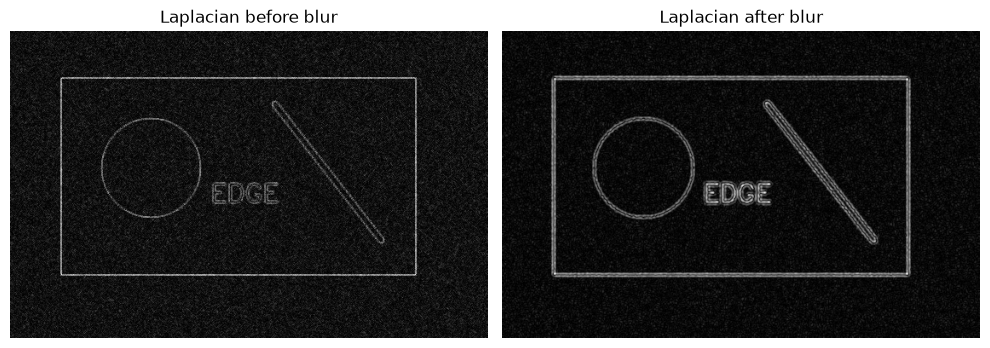

Mean absolute response: 97.66 -> 12.3


In [6]:
lap_raw = cv2.Laplacian(noisy, cv2.CV_32F, ksize=3)
lap_blur = cv2.Laplacian(blurred, cv2.CV_32F, ksize=3)
show_images([np.abs(lap_raw), np.abs(lap_blur)], ['Laplacian before blur', 'Laplacian after blur'], cols=2)
print('Mean absolute response:', round(float(np.abs(lap_raw).mean()), 2),
      '->', round(float(np.abs(lap_blur).mean()), 2))


## Step 3 — Turn gradients into thin edges with Canny
Canny applies gradient estimation, thinning, and hysteresis. Pixels above the high threshold start strong edges; eligible pixels above the low threshold can survive when connected to them. These are gradient thresholds, not input intensity thresholds. `L2gradient=True` uses Euclidean gradient magnitude.


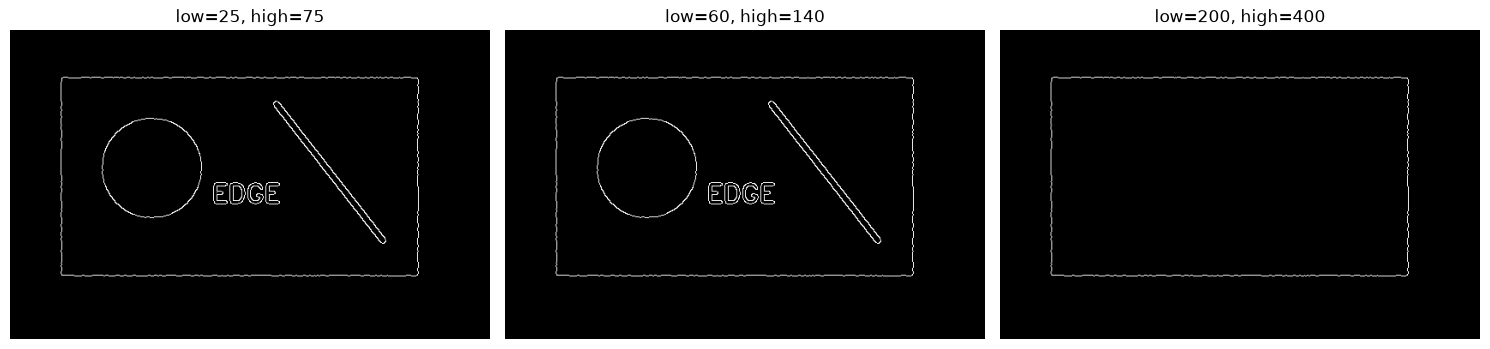

(25, 75) edge pixels: 2796
(60, 140) edge pixels: 2795
(200, 400) edge pixels: 1290


In [7]:
settings = [(25, 75), (60, 140), (200, 400)]
edge_maps = [cv2.Canny(blurred, low, high, L2gradient=True) for low, high in settings]
show_images(edge_maps, [f'low={a}, high={b}' for a, b in settings])
for setting, edges in zip(settings, edge_maps):
    print(setting, 'edge pixels:', np.count_nonzero(edges))
assert all(set(np.unique(e)).issubset({0, 255}) for e in edge_maps)


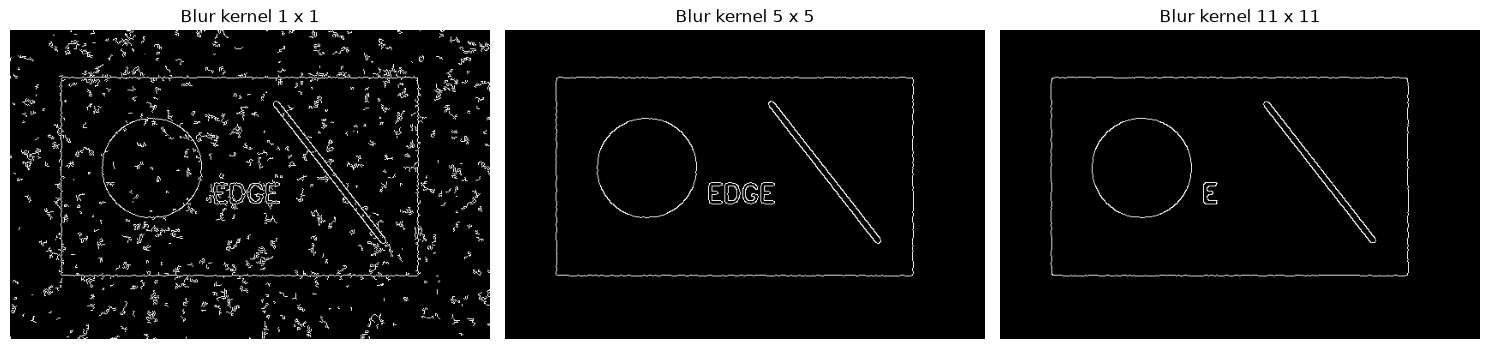

In [8]:
blur_sizes = [1, 5, 11]
blur_edges = []
for k in blur_sizes:
    candidate = noisy if k == 1 else cv2.GaussianBlur(noisy, (k, k), 0)
    blur_edges.append(cv2.Canny(candidate, 60, 140, L2gradient=True))
show_images(blur_edges, [f'Blur kernel {k} x {k}' for k in blur_sizes])


**Experiment:** change noise standard deviation from 12 to 25, then rerun from Step 1. Does raising thresholds or increasing blur preserve the small text better? A visually cleaner edge map may have discarded useful fine structure. Record both edge count and one detail you wanted to retain.


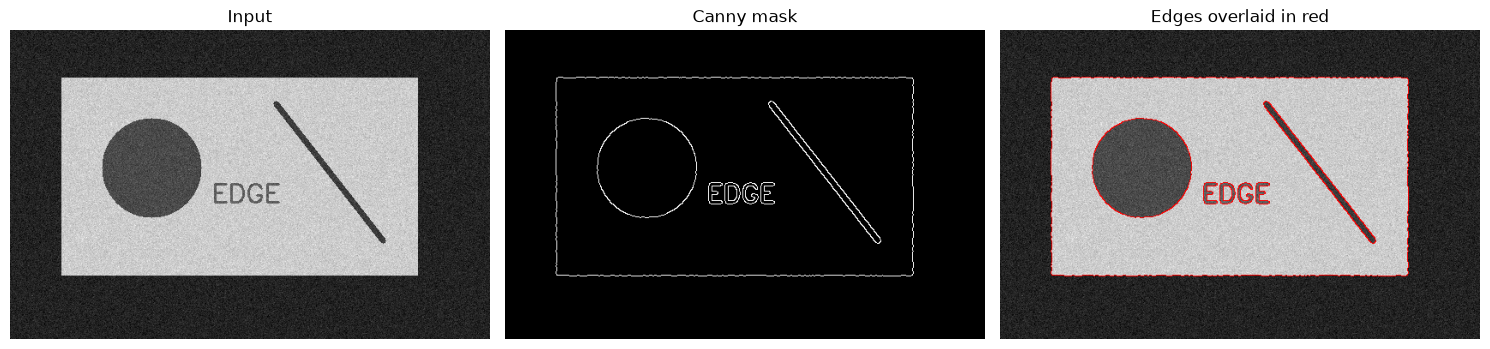

In [9]:
edges = edge_maps[1]
overlay = cv2.cvtColor(noisy, cv2.COLOR_GRAY2BGR)
overlay[edges > 0] = (0, 0, 255)
show_images([noisy, edges, overlay], ['Input', 'Canny mask', 'Edges overlaid in red'])


## Step 4 — Detect line segments with HoughLinesP
The probabilistic Hough transform votes for straight lines from edge pixels. `rho=1` is a one-pixel distance bin, `theta=np.pi/180` is a one-degree angle bin, and `threshold` is a vote cutoff. `minLineLength` rejects short segments; `maxLineGap` joins nearby collinear evidence. One physical border may generate several detections.


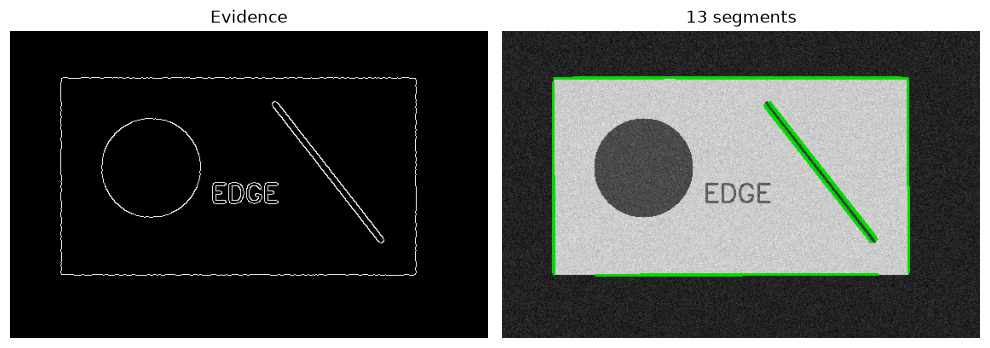

In [10]:
def detect_lines(edge_image, min_length=90, max_gap=12, votes=55):
    found = cv2.HoughLinesP(edge_image, 1, np.pi / 180, threshold=votes,
                            minLineLength=min_length, maxLineGap=max_gap)
    return np.empty((0, 4), dtype=np.int32) if found is None else found.reshape(-1, 4)

segments = detect_lines(edges)
line_view = cv2.cvtColor(noisy, cv2.COLOR_GRAY2BGR)
for x1, y1, x2, y2 in segments:
    cv2.line(line_view, (x1, y1), (x2, y2), (0, 220, 0), 2)
show_images([edges, line_view], ['Evidence', f'{len(segments)} segments'], cols=2)
assert len(segments) > 0, 'Expected long rectangle edges in the generated image.'


In [11]:
lengths = np.hypot(segments[:, 2] - segments[:, 0], segments[:, 3] - segments[:, 1])
angles = np.degrees(np.arctan2(segments[:, 3] - segments[:, 1], segments[:, 2] - segments[:, 0]))
for length, angle in zip(lengths, angles):
    print(f'length={length:6.1f} px, angle={angle:6.1f} degrees')
print('Empty-image handling:', detect_lines(np.zeros_like(edges)).shape)


length= 279.0 px, angle=   0.0 degrees
length= 128.0 px, angle=   0.0 degrees
length= 384.0 px, angle=   0.0 degrees
length= 171.0 px, angle=   0.0 degrees
length= 203.8 px, angle=  52.2 degrees
length= 223.0 px, angle= -90.0 degrees
length= 204.4 px, angle=  52.0 degrees
length= 200.8 px, angle=  51.9 degrees
length= 126.0 px, angle= -90.0 degrees
length= 101.0 px, angle= -90.0 degrees
length= 116.0 px, angle= -90.0 degrees
length= 271.0 px, angle=   0.0 degrees
length= 199.4 px, angle=  51.9 degrees
Empty-image handling: (0, 4)


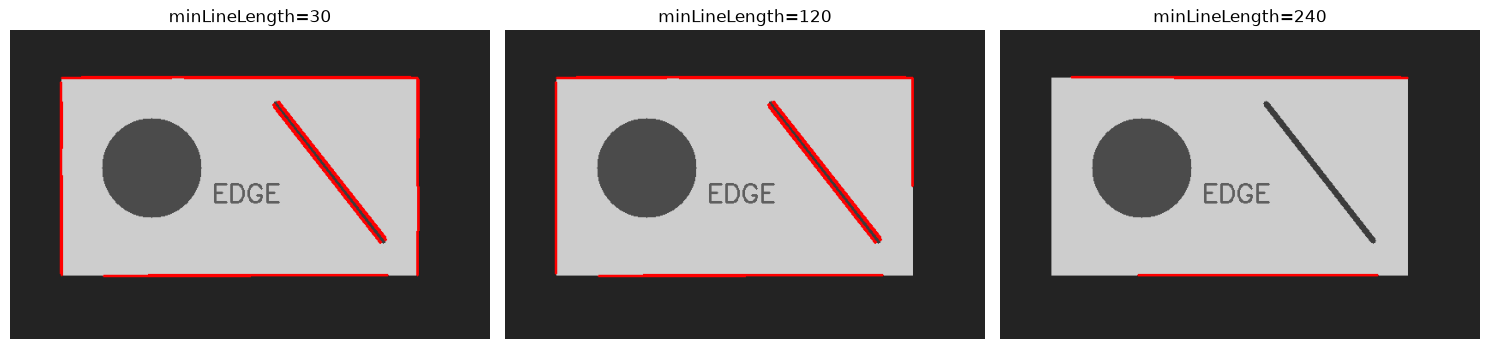

In [12]:
hough_views = []
for min_length in [30, 120, 240]:
    found = detect_lines(edges, min_length=min_length)
    canvas = cv2.cvtColor(clean, cv2.COLOR_GRAY2BGR)
    for x1, y1, x2, y2 in found:
        cv2.line(canvas, (x1, y1), (x2, y2), (0, 0, 255), 2)
    hough_views.append(canvas)
show_images(hough_views, ['minLineLength=30', 'minLineLength=120', 'minLineLength=240'])


## Step 5 — Mini-project: a document-border inspector
Keep long, nearly horizontal or vertical lines. This is a deliberately limited detector: it is suitable for a roughly aligned document, and it will miss a strongly rotated page. Use orientation tolerance rather than exact angle equality. The result is a border *candidate* overlay, not proof that a document exists.


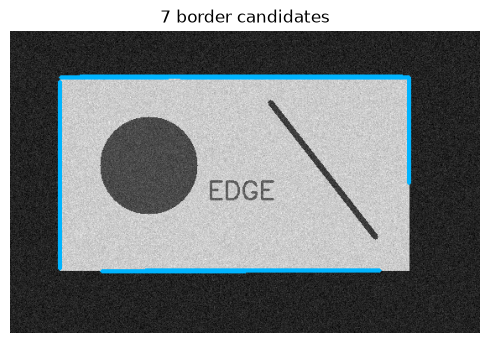

In [13]:
axis_angle = np.abs(angles) % 180
horizontal = np.minimum(axis_angle, 180 - axis_angle) < 8
vertical = np.abs(axis_angle - 90) < 8
keep = (lengths > 120) & (horizontal | vertical)
border_view = cv2.cvtColor(noisy, cv2.COLOR_GRAY2BGR)
for x1, y1, x2, y2 in segments[keep]:
    cv2.line(border_view, (x1, y1), (x2, y2), (255, 180, 0), 3)
show_images([border_view], [f'{np.count_nonzero(keep)} border candidates'])


In [14]:
out_dir = ROOT / 'outputs' / '07_edges'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'document_border_candidates.png', border_view)
print('Saved:', out_dir / 'document_border_candidates.png')


Saved: C:\Users\Hareram ray\AI\OpencvPractical\outputs\07_edges\document_border_candidates.png


### Pitfalls and debugging
- White Canny pixels are edge evidence; filled object masks require a different pipeline.
- A blank result can mean thresholds are too high, blur is too strong, or the input has little contrast.
- Hough returns `None` when no segments are detected. Handle it before reshaping.
- Lines do not directly give enclosed areas. Contours in Notebook 08 serve that purpose.

### Practice before opening the solutions
1. Count the fraction of Canny pixels for each threshold setting.
2. Write a detector that returns only diagonal segments between 25° and 65° from horizontal, regardless of endpoint order.
3. Compare Canny on the noisy input and the blurred input using the same thresholds. Explain why count alone does not determine quality.


## Worked solutions — run after your own attempt
Use modulo 180 because reversing a segment changes its direction by 180° but leaves the geometric line unchanged.


In [15]:
for (low, high), edge_image in zip(settings, edge_maps):
    print(f'{low:3}/{high:3}: {np.count_nonzero(edge_image) / edge_image.size:.2%} edge pixels')

all_segments = detect_lines(edges, min_length=35, votes=30)
all_angles = np.degrees(np.arctan2(all_segments[:, 3] - all_segments[:, 1],
                                 all_segments[:, 2] - all_segments[:, 0])) % 180
acute = np.minimum(all_angles, 180 - all_angles)
diagonals = all_segments[(acute >= 25) & (acute <= 65)]
print('Diagonal segments:', len(diagonals))


 25/ 75: 1.39% edge pixels
 60/140: 1.39% edge pixels
200/400: 0.64% edge pixels
Diagonal segments: 4


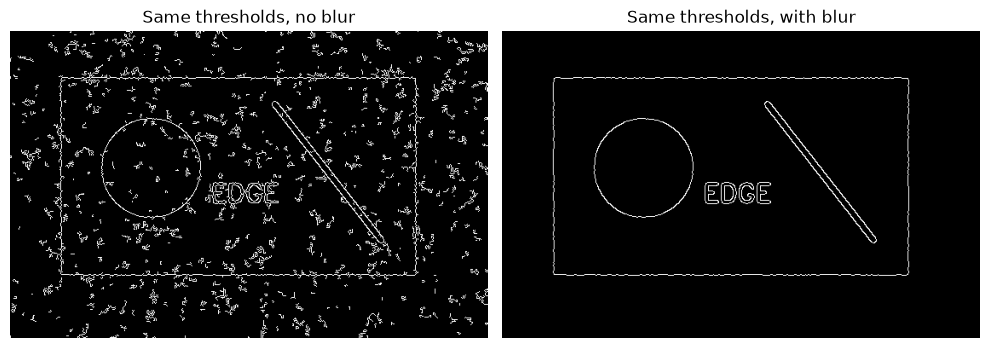

Counts: 11163 2795


In [16]:
without_blur = cv2.Canny(noisy, 60, 140, L2gradient=True)
with_blur = cv2.Canny(blurred, 60, 140, L2gradient=True)
show_images([without_blur, with_blur], ['Same thresholds, no blur', 'Same thresholds, with blur'], cols=2)
print('Counts:', np.count_nonzero(without_blur), np.count_nonzero(with_blur))
# Look for continuous real borders and fragmented noise, not only the smaller count.


### Reflection and next step
Explain why storing the derivative in uint8 can erase one side of an object. Which change removed false edges without losing the feature you wanted? Next, use closed boundaries to measure shapes.

Official references: [Sobel and Laplacian](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html), [Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html), [Hough lines](https://docs.opencv.org/4.x/d9/db0/tutorial_hough_lines.html).
